<a href="https://colab.research.google.com/github/halomohammed/Ml-assignment1/blob/main/RMS_Momentum.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

In [2]:
from google.colab import files

uploaded = files.upload()


Saving Position_Salaries.csv.csv to Position_Salaries.csv.csv


In [3]:
import pandas as pd

df = pd.read_csv("Position_Salaries.csv.csv")

df.head()


,Position,Level,Salary
0,Business Analyst,1,45000
1,Junior Consultant,2,50000
2,Senior Consultant,3,60000
3,Manager,4,80000
4,Country Manager,5,110000


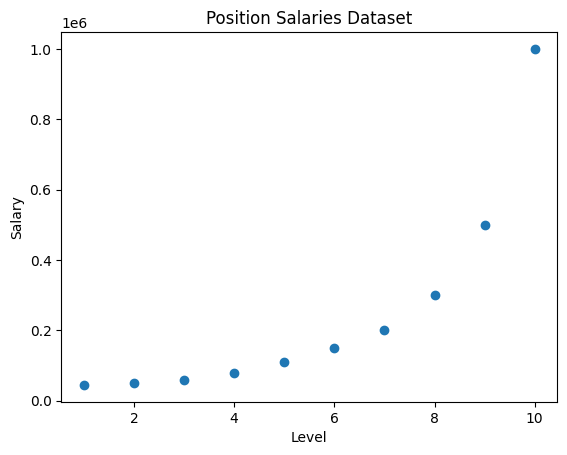

In [4]:
import matplotlib.pyplot as plt
import numpy as np

X = df["Level"].values
y = df["Salary"].values

plt.scatter(X, y)
plt.xlabel("Level")
plt.ylabel("Salary")
plt.title("Position Salaries Dataset")
plt.show()


In [5]:
import numpy as np

X = df["Level"].values
y = df["Salary"].values

w1 = 0
w2 = 0
b = 0

lr = 0.001
epochs = 500

beta = 0.9
momentum = 0.9
epsilon = 1e-8

sw1 = 0
sw2 = 0
sb = 0

vw1 = 0
vw2 = 0
vb = 0

n = len(X)

losses = []

for epoch in range(epochs):

    y_pred = w1 * X + w2 * (X**2) + b

    loss = np.mean((y - y_pred)**2)
    losses.append(loss)

    dw1 = (-2/n) * np.sum(X * (y - y_pred))
    dw2 = (-2/n) * np.sum((X**2) * (y - y_pred))
    db = (-2/n) * np.sum(y - y_pred)

    sw1 = beta * sw1 + (1-beta) * (dw1**2)
    sw2 = beta * sw2 + (1-beta) * (dw2**2)
    sb = beta * sb + (1-beta) * (db**2)

    vw1 = momentum * vw1 - lr * dw1 / (np.sqrt(sw1) + epsilon)
    vw2 = momentum * vw2 - lr * dw2 / (np.sqrt(sw2) + epsilon)
    vb = momentum * vb - lr * db / (np.sqrt(sb) + epsilon)

    w1 += vw1
    w2 += vw2
    b += vb


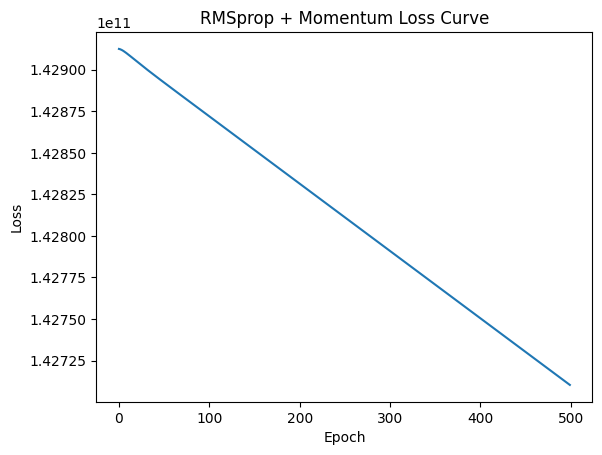

In [6]:
plt.plot(losses)
plt.xlabel("Epoch")
plt.ylabel("Loss")
plt.title("RMSprop + Momentum Loss Curve")
plt.show()
